In [1]:
import numpy as np
import netCDF4 as nc
import xarray as xr
import os
import json
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.lines as mlines
from matplotlib.colors import TwoSlopeNorm
import pandas as pd
import cartopy.crs as ccrs
# from ladcp_tools import *                  # load_all_stations, ...
# from tools import *                        # setup_map, load_satellite, load_eddies, plot_eddies
from tools_eg import *

In [2]:
EXTENT = None  # e.g. [10, 20, -42, -34]
lon_min, lon_max, lat_min, lat_max = 8, 25, -41, -34
extent = [lon_min, lon_max, lat_min, lat_max]

CRUISE_START = "2026-05-14"
CRUISE_END   = "2026-07-27"

ft = 10
# ADT colours: white exactly at 0, but each side stretched separately
# (ADT here is ~ -0.3 .. +1.5 m). Lower ADT_MIN -> darker cyclone blues,
# raise ADT_MAX -> fewer saturated anticyclone reds.
ADT_MIN, ADT_MAX = -0.3, 1.5
adt_norm = TwoSlopeNorm(vmin=ADT_MIN, vcenter=0, vmax=ADT_MAX)
levels = np.arange(ADT_MIN, ADT_MAX + 0.001, 0.02)
adt_ticks = [-0.3, 0, 0.3, 0.6, 0.9, 1.2, 1.5]

crs = ccrs.PlateCarree()
proj = ccrs.Mercator(central_longitude=(lon_min + lon_max) / 2)


BASE = Path("/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS")
DIR_SADCP = BASE / "data/SADCP"
SADCP_FILES = {"OS150": DIR_SADCP / "WHIRLS_NB150_TOT_osite.nc",   # full cruise (README)
               "OS38": DIR_SADCP / "WHIRLS_BB38_TOT_osite.nc"}
DIR_LADCP = BASE / "data/LADCP/traitement_avec_SADCP"
DIR_SSH = BASE / "data/SSH"
DIR_EDDIES = {"TOEDDIES_better_ADT": BASE / "data/TOEDDIES/TOEDDIES_better_ADT",
              "TOEDDIES": BASE / "data/TOEDDIES/TOEDDIES"}
FNAME_BATHY = BASE / "data/bathymetry/etopo2.nc"
DIR_TRACKS = BASE / "figures/eddy_tracks"
DIR_CODE = BASE / "analysis"          # where ladcp_tools.py lives

DIR_DRIFTERS =  BASE / "data/DRIFTERS/drifters"
DIR_GEOJSON = BASE / "data/DRIFTERS/drifters_tracks.geojson"

DIR_MVP = BASE / "data/MVP_Data_processed"


# Animation
ANIM_START = "2026-07-01"                 # first drifter deployment
ANIM_END   = CRUISE_END                   # days without an ADT file are skipped
TAIL_DAYS  = 5                            # length of the track drawn behind each drifter (None = whole track)

# Drifter data: "csv" (folder of CSV snapshots, DIR_DRIFTERS) or "geojson" (DIR_GEOJSON)
DRIFTER_SOURCE = "csv"
FIRST_LAUNCH = "2026-07-01 05:00"         # fixes before this are bench tests (as in Solange's script)
FRAME_DIR = "whirls_drifters_animation"
OUT_MP4   = "whirls_drifters_animation.mp4"
FPS = 2                                   # frames (days) per second

os.makedirs(FRAME_DIR, exist_ok=True)

In [3]:
# ----------------------------------------------------------------------------
# Things loaded ONCE (they don't change from day to day)
# ----------------------------------------------------------------------------
# Bathymetry
bathymetry_data = xr.open_dataset(FNAME_BATHY)
lon_subset = bathymetry_data["lon"].sel(lon=slice(lon_min, lon_max))
lat_subset = bathymetry_data["lat"].sel(lat=slice(lat_min, lat_max))
depth_subset = bathymetry_data["topo"].sel(lon=slice(lon_min, lon_max),
                                           lat=slice(lat_min, lat_max))

# File lists
daily_ssh_files = sorted(os.listdir(DIR_SSH))
eddy_files_better = sorted(os.listdir(DIR_EDDIES['TOEDDIES_better_ADT']))
eddy_files_std = sorted(os.listdir(DIR_EDDIES['TOEDDIES']))

type_SADCP = "OS38"
sadcp = nc.Dataset(SADCP_FILES[type_SADCP])


In [4]:
transect = "Transect 12"
transect_path = f'/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/data/MVP_Data_processed/{transect}/'
out_dir = f'/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/figures/mvp/{transect}/'
if not os.path.isdir(out_dir):
    os.mkdir(out_dir)

In [5]:
files = sorted(Path(transect_path).glob("*.csv"))
dfs = []
for k, f in enumerate(files):
    df = pd.read_csv(f)
    df["CAST"] = k          # one processed CSV file = one MVP cast
    dfs.append(df)
mvp_trans = pd.concat(dfs, ignore_index=True)
print(len(files), "files")

118 files


In [6]:
sadcp = cascade_add_time(xr.open_dataset(SADCP_FILES[type_SADCP]))
sadcp = sadcp.sortby("time")
sadcp = sadcp.isel(time=~sadcp.indexes["time"].duplicated())
# (no global sort/drop_duplicates: each cast is sorted in process_transect)

sadcp_tr  = sadcp_for_transect(mvp_trans, sadcp)
sadcp_mvp = sadcp_on_mvp_times(mvp_trans, sadcp_tr, max_gap="30min")

mvp_trans["LON (°E)"] = mvp_trans["LON (°E)"].fillna(pd.Series(sadcp_mvp["LONGITUDE"].values, index=mvp_trans.index))
mvp_trans["LAT (°N)"] = mvp_trans["LAT (°N)"].fillna(pd.Series(sadcp_mvp["LATITUDE"].values, index=mvp_trans.index))

print("MVP samples without position:", mvp_trans["LAT (°N)"].isna().sum(), "of", len(mvp_trans))

MVP samples without position: 0 of 494501


In [7]:
sadcp_tr_window = cascade_to_window_format(sadcp_tr, pgood_min=50)
sadcp_mvp_processed = sadcp_window(type_SADCP, sadcp=sadcp_tr_window)
print(len(sadcp_mvp_processed["time"]), "SADCP profiles")   

  ! PGOOD_ADCP is all 0 in this file -> PGOOD mask skipped
Calculating Mean
146 SADCP profiles


eddy crossed: cyclone
118 casts used


/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/analysis/tools_eg.py:996: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pc = ax.pcolormesh(xkm, p, data, cmap=cmap, shading="nearest",


  TOEddies center at -16 km: outside section (-2-272 km) -> not marked


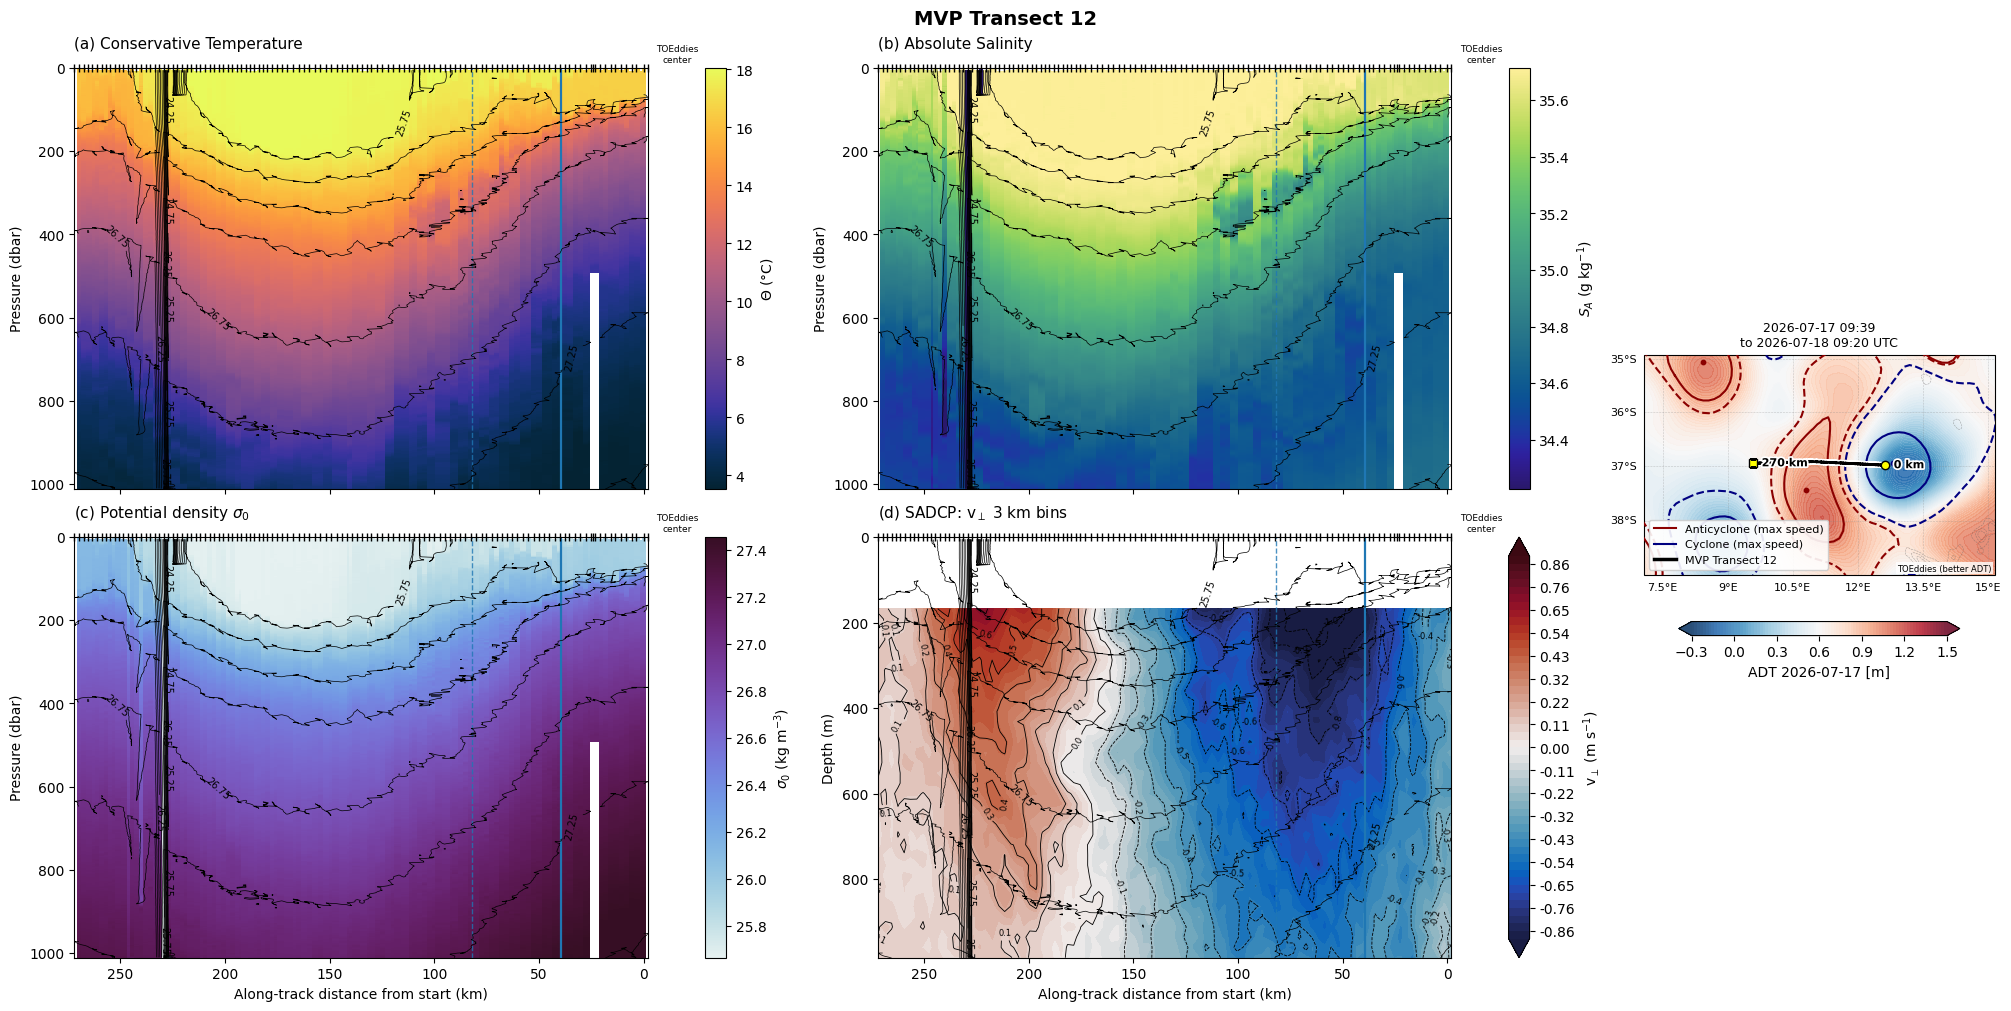

In [8]:
# ---------------- map background for the combined figure ----------------
out_dir = str(BASE / "figures/mvp") + f"/{transect}/"

date = pd.to_datetime(mvp_trans["TIME"]).median().strftime("%Y-%m-%d")
date_compact = date.replace("-", "")
ssh = load_satellite(DIR_SSH / [f for f in daily_ssh_files if date in f or date_compact in f][0])
eddy_files, eddy_source = get_eddy_files(date_compact, date)

edd = eddy_on_transect(eddy_files, mvp_trans["LON (°E)"].values, mvp_trans["LAT (°N)"].values)
print("eddy crossed:", None if edd is None else ("cyclone" if edd["cyc"] else "anticyclone"))


# ---------------- SADCP for zeta (PV) ----------------
ds = sadcp_tr                      # ADCP subset for this transect (sadcp_mvp is ~1 GB, not needed)
zdim = ds["depth"].dims[0]
u = ds["UVEL_ADCP_CORTIDE"].transpose("time", zdim).values
v = ds["VVEL_ADCP_CORTIDE"].transpose("time", zdim).values
pg = ds["PGOOD_ADCP"].transpose("time", zdim).values

u[pg < 50] = np.nan
v[pg < 50] = np.nan

args = [ssh, eddy_files, transect, eddy_source, adt_ticks, date, levels]
# ---------------- map + Theta / S_A / sigma0 ----------------
sec, fig, axs = process_transect(
    mvp_trans, adcp=sadcp_mvp_processed, cast_col="CAST",
    map_draw=draw_background,      # map_extent=extent  -> whole region instead of zoom
    map_args = args,
    title=f"MVP {transect}",
    eddy=edd,
    savepath=out_dir + f"{transect}_sections_hydro_adcp.png")
plt.show()

In [14]:
# # Ertel PV (computed in the call above, stored in sec["q"]) as a separate figure
# fig_pv, axs_pv = plot_section(sec, title=f"MVP {transect}",
#                               savepath=out_dir + f"{transect}_sections_PV.png")
# plt.show()

In [321]:
# ADT_MIN, ADT_MAX = -0.3, 1.2
# adt_norm = TwoSlopeNorm(vmin=ADT_MIN, vcenter=0, vmax=ADT_MAX)
# levels = np.arange(ADT_MIN, ADT_MAX + 0.001, 0.02)
# adt_ticks = [-0.3, 0, 0.3, 0.6, 0.9, 1.2]

# date = pd.to_datetime(mvp_trans['TIME']).median().strftime("%Y-%m-%d")
# date_str = date
# date_compact = date.replace("-", "")

# # --- ADT of the day ---
# ssh_match = [f for f in daily_ssh_files if date_str in f or date_compact in f]

# ssh = load_satellite(DIR_SSH / ssh_match[0])

# # --- Eddies of the day ---
# eddy_files, eddy_source = get_eddy_files(date_compact, date_str)

# # Fixed figure size and no bbox_inches="tight" so all frames are identical in size
# fig = plt.figure(figsize=(7, 4.8), dpi=150)
# ax = fig.add_subplot(111, projection=proj)
# setup_map(ax, extent, f"ADT, Eddies and SADCP: {date_str}", crs, ft)

# bathy = ax.contour(lon_subset, lat_subset, depth_subset,
#                     colors="grey", linewidths=0.6, transform=crs)
# ax.clabel(bathy, fontsize=4)

# c = ax.contourf(ssh["lon"], ssh["lat"], ssh["adt"][0],
#                 levels=levels, cmap="RdBu_r", extend="both",
#                 transform=crs)
# ax.scatter(sadcp_mvp["LONGITUDE"],sadcp_mvp["LATITUDE"], transform=crs, color="black", s=1, zorder=1000, label="Transect 1")
# if eddy_files:
#     anti, cyc = load_eddies(eddy_files)
#     plot_eddies(ax, anti, "red", crs)
#     plot_eddies(ax, cyc, "blue", crs)
# # Small label so you can see which eddy product each frame uses
# if eddy_source:
#     ax.text(0.01, 0.01, eddy_source, transform=ax.transAxes, fontsize=5,
#             ha="left", va="bottom", zorder=102,
#             bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1))

# # --- Legend (proxy handles, so it is the same on every frame) ---
# handles = [
#     mlines.Line2D([], [], color="red", label="Anticyclones"),
#     mlines.Line2D([], [], color="blue", label="Cyclones"),
#      mlines.Line2D([], [], color="black", label=f"{transect}"),
# ]
# leg = ax.legend(handles=handles, fontsize="x-small", loc="upper right",
#             framealpha=0.85)
# leg.set_zorder(1000)
# cb = fig.colorbar(c, ax=ax, shrink=0.6, ticks=adt_ticks, spacing="proportional")
# cb.set_label("ADT [m]")
# plt.savefig(f"/Users/emmagurcan/Documents/France/ENS/Speich/WHIRLS/figures/mvp/{transect}_SADCP")
# plt.show()


In [ ]:




# # ---------------------------------------------------------------------------
# # 4. Optional: cross-track ADCP velocity on the section grid
# # ---------------------------------------------------------------------------
# def adcp_cross_track_on_section(sec, adcp_lon, adcp_lat, adcp_depth, adcp_u, adcp_v,
#                                 dx_bin=1000.0, extrap_surface=True):
#     """
#     adcp_u/v: (time, depth) arrays, e.g. adcp_cut.uvel_adcp.values.
#     Returns v_perp on (p, cast) grid; v_perp positive to the LEFT of the ship track direction.
#     extrap_surface: ADCP misses the top ~15-20 m (blanking); copy the shallowest good bin
#     upward so PV is defined in the mixed layer (standard practice, but check it is sensible).
#     """
#     ex = sec["xdir"]
#     x_a, _ = along_track_x(np.asarray(adcp_lon), np.asarray(adcp_lat),
#                            sec["lon"][0], sec["lat"][0], ex)
#     v_perp = -np.asarray(adcp_u) * ex[1] + np.asarray(adcp_v) * ex[0]  # y_hat = (-ex_n, ex_e)

#     # bin-average ADCP along x (removes ping noise), then interpolate onto casts/pressure
#     edges = np.arange(x_a.min(), x_a.max() + dx_bin, dx_bin)
#     xb = 0.5 * (edges[1:] + edges[:-1])
#     ib = np.digitize(x_a, edges) - 1
#     vb = np.full((len(xb), v_perp.shape[1]), np.nan)
#     for k in range(len(xb)):
#         if np.any(ib == k):
#             vb[k] = np.nanmean(v_perp[ib == k], axis=0)

#     z_sec = -gsw.z_from_p(sec["p"], np.nanmean(sec["lat"]))  # depth (m) of pressure grid
#     out = np.full((len(sec["p"]), len(sec["x"])), np.nan)
#     tmp = np.full((vb.shape[1], len(sec["x"])), np.nan)
#     for d in range(vb.shape[1]):
#         ok = np.isfinite(vb[:, d])
#         if ok.sum() > 2:
#             tmp[d] = np.interp(sec["x"], xb[ok], vb[ok, d])
#             far = (sec["x"] < xb[ok][0] - dx_bin) | (sec["x"] > xb[ok][-1] + dx_bin)
#             tmp[d, far] = np.nan
#     dep = np.asarray(adcp_depth, float)
#     for j in range(len(sec["x"])):
#         ok = np.isfinite(tmp[:, j])
#         if ok.sum() > 2:
#             out[:, j] = np.interp(z_sec, dep[ok], tmp[ok, j],
#                                   left=None if extrap_surface else np.nan, right=np.nan)
#     return out


# ---------------------------------------------------------------------------
# 5. Ertel PV
# ---------------------------------------------------------------------------
# def nan_smooth(a, size, axis):
#     """Box-car smoothing that ignores NaNs."""
#     if size <= 1:
#         return a
#     w = np.isfinite(a).astype(float)
#     num = uniform_filter1d(np.where(w > 0, a, 0.0), size, axis=axis, mode="nearest")
#     den = uniform_filter1d(w, size, axis=axis, mode="nearest")
#     out = num / np.where(den > 0, den, np.nan)
#     out[w == 0] = np.nan
#     return out


# def ertel_pv(sec, v_perp=None, smooth_z=5, smooth_x=3):
#     """
#     Adds b, N2, bx, zeta, q, q_vert, q_bc to `sec`.
#     smooth_z: points (dbar bins) for vertical smoothing; smooth_x: number of casts.
#     MVP casts are ~1-2 km apart and the gradients are noisy, so some smoothing is needed.
#     """
#     lat0 = np.nanmean(sec["lat"])
#     f = 2 * OMEGA * np.sin(np.deg2rad(lat0))
#     z = gsw.z_from_p(sec["p"], lat0)  # negative, metres

#     sig = nan_smooth(nan_smooth(sec["sig0"], smooth_z, 0), smooth_x, 1)
#     b = -G * (sig - np.nanmean(sig)) / RHO0

#     N2 = np.gradient(b, z, axis=0)
#     bx = np.gradient(b, sec["x"], axis=1)       # non-uniform cast spacing is fine

#     if v_perp is not None:
#         v = nan_smooth(nan_smooth(v_perp, smooth_z, 0), smooth_x, 1)
#         zeta = np.gradient(v, sec["x"], axis=1)
#     else:
#         zeta = np.zeros_like(b)

#     q_vert = (f + zeta) * N2
#     q_bc = -bx ** 2 / f
#     sec.update(f=f, z=z, b=b, N2=N2, bx=bx, zeta=zeta,
#                q_vert=q_vert, q_bc=q_bc, q=q_vert + q_bc)
#     return sec